In [4]:
# -----------------------------------------------------------------------
# 0. Libraries and Reproducibility setup
# -----------------------------------------------------------------------

import sys
# import os
import warnings
import numpy as np
import matplotlib
import scipy
import sklearn
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (Matern, ConstantKernel, WhiteKernel)
from scipy.stats import norm, skew, spearmanr, qmc
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42
rng = np.random.default_rng(SEED)
SK_RANDOM_STATE = np.random.RandomState(SEED)  # sklearn wants a RandomState

print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()

# ---------------------------------------------------------------- 
# Figures settings
# ---------------------------------------------------------------- 
SURFACE, INK, INK2, MUTED, GRIDC = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e6e5e1"
BLUE, ORANGE, AQUA, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#e87ba4"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRIDC, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



n = 32 (20 initial + 12 queried); newest x = [0.999999 0.999999 0.999999 0.999999], y = 8662.405001
best observed: row 29, x = [1. 1. 1. 1.], y = 8662.482500
newest ranks 2 of 32; skew raw 1.46, skew log -0.50




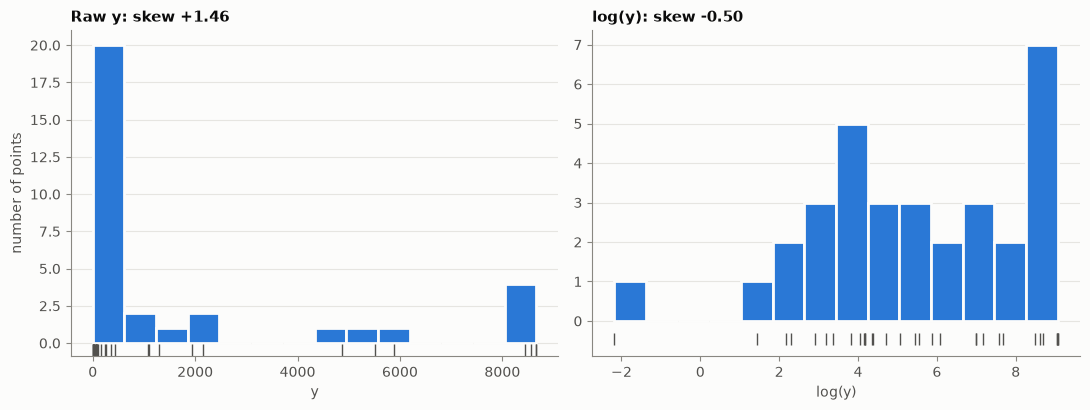

In [5]:
# -----------------------------------------------------------------------
# 1. Data
# -----------------------------------------------------------------------
X = np.load('..\Function_5_Data\Week_13_Data/F5_Week_13_inputs.npy')
y = np.load('..\Function_5_Data\Week_13_Data/F5_Week_13_outputs.npy')
n, d = X.shape
N_INITIAL = 20
W12 = n - 1                         # row 31: the week-12 query (newest reading)
best = int(np.argmax(y))            # row 29: the corner (1, 1, 1, 1)
CORNER = np.ones(d)
BEST = y[best]
print(f"n = {n} ({N_INITIAL} initial + {n - N_INITIAL} queried); newest x = {X[W12]}, y = {y[W12]:.6f}")
print(f"best observed: row {best}, x = {np.round(X[best], 9)}, y = {BEST:.6f}")
print(f"newest ranks {int((y > y[W12]).sum()) + 1} of {n}; skew raw {skew(y):.2f}, skew log {skew(np.log(y)):.2f}")
assert np.allclose(X[best], CORNER, atol=1e-12) and np.allclose(X[W12], CORNER, atol=2e-6), "layout changed"
EXACT = lambda M, j_skip=None: np.all(np.abs(M - 1.0) < 1e-9, axis=1)

print('\n')


# Fig 1: target distribution
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (title, v, xl) in zip(axes, [("Raw y", y, "y"), ("log(y)", np.log(y), "log(y)")]):
    ax.hist(v, bins=14, color=BLUE, edgecolor=SURFACE, linewidth=2)
    ax.plot(v, np.full(n, -0.45), "|", color=INK2, markersize=9, clip_on=False)
    ax.set_title(f"{title}: skew {skew(v):+.2f}"); ax.set_xlabel(xl)
    ax.set_ylim(bottom=-0.9); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("number of points")
fig.tight_layout()


MODELS (LOO with hyperparameters fixed; errors in raw y)
  log-iso  ls=[0.533]  noise sd (own scale, normalised)=0.0001  own-scale LOO RMSE/std=0.571  Spearman=0.841  raw RMSE all=734  raw RMSE top 6=540
  log-ARD  ls=[1.886 0.218 0.76  0.626]  noise sd (own scale, normalised)=0.0001  own-scale LOO RMSE/std=0.574  Spearman=0.852  raw RMSE all=976  raw RMSE top 6=1804
  raw-iso  ls=[2.051]  noise sd (own scale, normalised)=0.0107  own-scale LOO RMSE/std=0.095  Spearman=0.856  raw RMSE all=283  raw RMSE top 6=292
  raw-ARD  ls=[1.963 4.357 1.772 1.817]  noise sd (own scale, normalised)=0.0132  own-scale LOO RMSE/std=0.074  Spearman=0.854  raw RMSE all=220  raw RMSE top 6=105
  raw-ARD fitted noise sd = 39.2 (0.45% of the best value)
  if that noise were real, two readings 2e-6 apart would differ by N(0, 55.4); the chance of a difference as small as 0.0775 is 0.0011 (897 to 1 against)




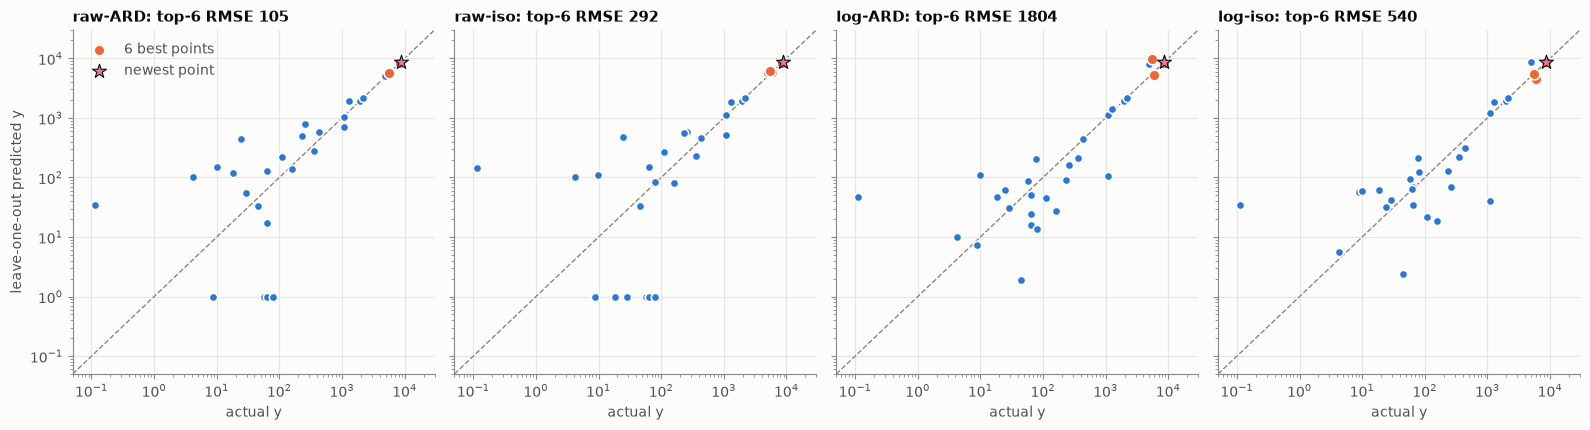

In [6]:
# ---------------------------------------------------------------- 
# Models
# ---------------------------------------------------------------- 
step = X[W12] - X[best]
dy = y[W12] - BEST
def fit(Xf, t, ard):
    k = (ConstantKernel(1.0, (1e-3, 1e3)) * Matern(length_scale=np.ones(d) if ard else 1.0,
                                      length_scale_bounds=(1e-2, 1e2), nu=2.5)
         + WhiteKernel(1e-4, (1e-8, 1e-1)))
    return GaussianProcessRegressor(kernel=k, normalize_y=True, alpha=1e-10,
                                    n_restarts_optimizer=20, random_state=SEED).fit(Xf, t)

TARGETS = {"log": (np.log, np.exp), "raw": (lambda v: v.copy(), lambda m: m)}
models, loos = {}, {}
top = np.argsort(-y)[:6]
print("\nMODELS (LOO with hyperparameters fixed; errors in raw y)")
for tname, (f, back) in TARGETS.items():
    t = f(y)
    for ard in (False, True):
        key = f"{tname}-{'ARD' if ard else 'iso'}"
        gp = fit(X, t, ard)
        mu = np.empty(n)
        for i in range(n):
            keep = np.arange(n) != i
            g = GaussianProcessRegressor(kernel=gp.kernel_, optimizer=None, normalize_y=True,
                                         alpha=1e-10).fit(X[keep], t[keep])
            mu[i] = g.predict(X[i:i + 1])[0]
        yb = back(mu)
        models[key], loos[key] = gp, yb
        ls = np.atleast_1d(gp.kernel_.k1.k2.length_scale)
        print(f"  {key:8s} ls={np.round(ls, 3)}  noise sd (own scale, normalised)={np.sqrt(gp.kernel_.k2.noise_level):.4f}  "
              f"own-scale LOO RMSE/std={np.sqrt(np.mean((t - mu) ** 2)) / t.std():.3f}  "
              f"Spearman={spearmanr(y, yb)[0]:.3f}  raw RMSE all={np.sqrt(np.mean((y - yb) ** 2)):.0f}  "
              f"raw RMSE top 6={np.sqrt(np.mean((y[top] - yb[top]) ** 2)):.0f}")
raw_noise_sd = np.sqrt(models["raw-ARD"].kernel_.k2.noise_level) * y.std()
print(f"  raw-ARD fitted noise sd = {raw_noise_sd:.1f} ({100 * raw_noise_sd / y.max():.2f}% of the best value)")
sd_diff = raw_noise_sd * np.sqrt(2)
p_small = 2 * norm.cdf(abs(dy) / sd_diff) - 1
print(f"  if that noise were real, two readings 2e-6 apart would differ by N(0, {sd_diff:.1f}); the chance of a difference "
      f"as small as {abs(dy):.4f} is {p_small:.4f} ({1 / p_small:,.0f} to 1 against)")

def predict(key, Z):
    m, s = models[key].predict(np.atleast_2d(Z), return_std=True)
    return (np.exp(m), s) if key.startswith("log") else (m, s)

def p_improve(key, Z):
    m, s = models[key].predict(np.atleast_2d(Z), return_std=True)
    thr = np.log(BEST) if key.startswith("log") else BEST
    return norm.sf((thr - m) / np.maximum(s, 1e-12))

def ei_best(key, Z):
    m, s = models[key].predict(np.atleast_2d(Z), return_std=True)
    if key.startswith("log"):
        return np.full(len(m), np.nan)
    s = np.maximum(s, 1e-12); z = (m - BEST) / s
    return (m - BEST) * norm.cdf(z) + s * norm.pdf(z)

print('\n')

# Fig 2: LOO predicted vs actual, raw y, log axes
KEYS = ["raw-ARD", "raw-iso", "log-ARD", "log-iso"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4), sharey=True)
for ax, key in zip(axes, KEYS):
    yb = np.maximum(loos[key], 1)
    lim = [5e-2, 3e4]
    ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
    ax.scatter(y, yb, s=36, color=BLUE, edgecolor=SURFACE, linewidth=1.2, zorder=3)
    ax.scatter(y[top], yb[top], s=60, color=ORANGE, edgecolor=SURFACE, linewidth=1.2, zorder=4, label="6 best points")
    ax.scatter(y[W12], yb[W12], s=110, marker="*", color=MAGENTA, edgecolor=INK, linewidth=0.8, zorder=5, label="newest point")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_title(f"{key}: top-6 RMSE {np.sqrt(np.mean((y[top] - loos[key][top]) ** 2)):.0f}")
    ax.set_xlabel("actual y")
axes[0].set_ylabel("leave-one-out predicted y")
axes[0].legend(frameon=False, loc="upper left", labelcolor=INK2)
fig.tight_layout()

In [7]:
# ---------------------------------------------------------------- 
# Week-12 prediction check
# ---------------------------------------------------------------- 

print(f"\nWEEK-12 PREDICTIONS at the newest point (models refitted on the first {W12} rows); observed {y[W12]:.4f}")
prev = {}
for key in ["raw-ARD", "raw-iso", "log-ARD", "log-iso"]:
    tname, kind = key.split("-")
    f, back = TARGETS[tname]
    g = fit(X[:W12], f(y[:W12]), kind == "ARD")
    m, s = g.predict(X[W12:W12 + 1], return_std=True)
    pred = back(m)[0]
    sd_raw = s[0] if tname == "raw" else s[0] * pred
    prev[key] = (pred, sd_raw)
    print(f"  {key:8s} predicted {pred:8.1f} +/- {sd_raw:6.1f}   error {y[W12] - pred:+7.1f}   z = {(y[W12] - pred) / sd_raw:+.2f}")


WEEK-12 PREDICTIONS at the newest point (models refitted on the first 31 rows); observed 8662.4050
  raw-ARD  predicted   8609.9 +/-   44.7   error   +52.5   z = +1.17
  raw-iso  predicted   8618.2 +/-   37.1   error   +44.2   z = +1.19
  log-ARD  predicted   8639.2 +/-   41.2   error   +23.2   z = +0.56
  log-iso  predicted   8662.4 +/-    3.2   error    -0.0   z = -0.01



OBSERVATIONS ON THE LINES THROUGH THE CORNER (other three inputs exactly 1; the near-duplicate is excluded)
  x1: (0.7810: 5875), (0.9888: 8449), (1.0000: 8662)
  x2: (0.9942: 8551), (1.0000: 8662)
  x3: (1.0000: 8662)
  x4: (0.7295: 5521), (1.0000: 8662)
  x1: last step 0.9888 -> 1.0000: y 8449 -> 8662, slope 18,937 per unit (2.46% of the corner value)
  x2: last step 0.9942 -> 1.0000: y 8551 -> 8662, slope 19,147 per unit (1.29% of the corner value)
  sum of the four partials (from the 1e-6 pair): 77,499; minus x1 and x2 leaves 39,415 for x3 + x4 (19,708 each if equal)
  x1 slope over the earlier, longer step 0.7810 -> 0.9888: 12,392 per unit (against 18,937 over the last step: the slope increases towards the corner)




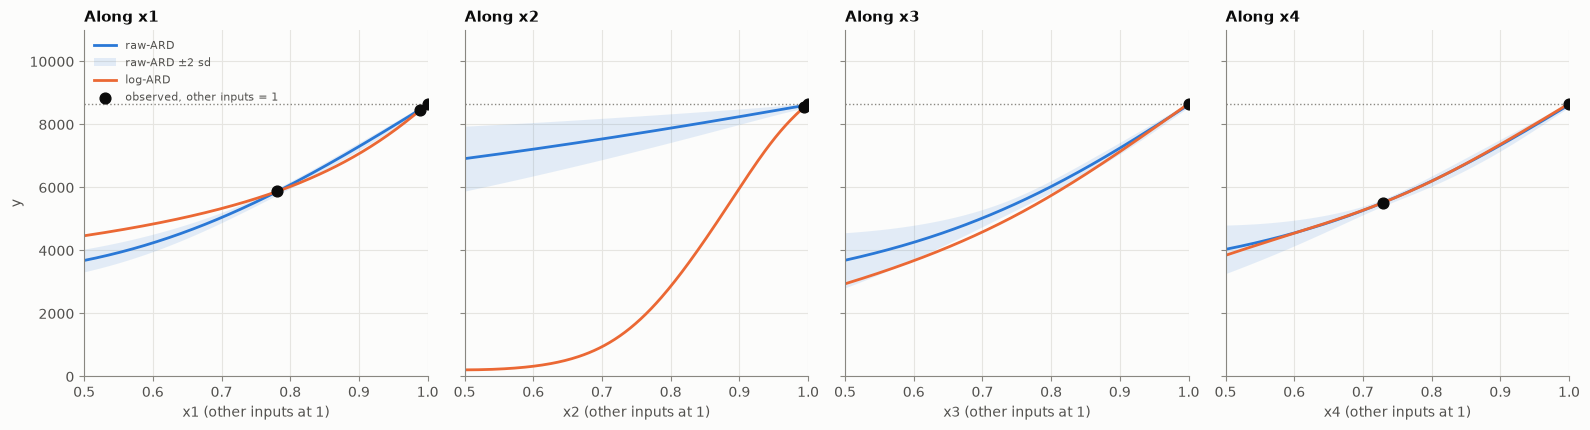

In [8]:
# ---------------------------------------------------------------- slopes on the lines through the corner
print("\nOBSERVATIONS ON THE LINES THROUGH THE CORNER (other three inputs exactly 1; the near-duplicate is excluded)")
slopes = {}
for j in range(d):
    others = [k for k in range(d) if k != j]
    on = np.where(EXACT(X[:, others]))[0]
    on = on[np.argsort(X[on, j])]
    on = np.array([i for i in on if i != W12])
    print(f"  x{j + 1}: " + ", ".join(f"({X[i, j]:.4f}: {y[i]:.0f})" for i in on))
    slopes[j] = [(X[i, j], y[i]) for i in on]
slope_val = {}
for j in (0, 1):
    (xa, ya), (xb_, yb_) = slopes[j][-2], slopes[j][-1]
    slope_val[j] = (yb_ - ya) / (xb_ - xa)
    print(f"  x{j + 1}: last step {xa:.4f} -> {xb_:.4f}: y {ya:.0f} -> {yb_:.0f}, slope {slope_val[j]:,.0f} per unit "
          f"({100 * (yb_ - ya) / yb_:.2f}% of the corner value)")
sum_partials = -dy / abs(step[0])
rest = sum_partials - slope_val[0] - slope_val[1]
print(f"  sum of the four partials (from the 1e-6 pair): {sum_partials:,.0f}; minus x1 and x2 leaves {rest:,.0f} for x3 + x4 "
      f"({rest / 2:,.0f} each if equal)")
(xa, ya), (xb_, yb_), (xc, yc) = slopes[0][0], slopes[0][-2], slopes[0][-1]
print(f"  x1 slope over the earlier, longer step {xa:.4f} -> {xb_:.4f}: {(yb_ - ya) / (xb_ - xa):,.0f} per unit "
      f"(against {slope_val[0]:,.0f} over the last step: the slope increases towards the corner)")

print('\n')
# Fig 3: slices through the corner along each input (readings exactly on each line)
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4), sharey=True)
xs = np.linspace(0.5, 1.0, 200)
for j, ax in enumerate(axes):
    Z = np.tile(CORNER, (len(xs), 1)); Z[:, j] = xs
    for key, col in [("raw-ARD", BLUE), ("log-ARD", ORANGE)]:
        m, s = predict(key, Z)
        ax.plot(xs, m, color=col, lw=2, label=key)
        if key == "raw-ARD":
            ax.fill_between(xs, m - 2 * s, m + 2 * s, color=col, alpha=0.12, lw=0, label="raw-ARD ±2 sd")
    others = [k for k in range(d) if k != j]
    on_line = EXACT(X[:, others]) & (np.arange(n) != W12)
    ax.scatter(X[on_line, j], y[on_line], s=60, color=INK, zorder=4, label="observed, other inputs = 1")
    ax.axhline(BEST, color=MUTED, lw=1, ls=":")
    ax.set_xlabel(f"x{j + 1} (other inputs at 1)"); ax.set_title(f"Along x{j + 1}")
    ax.set_xlim(0.5, 1.0); ax.set_ylim(0, 11000)
axes[0].set_ylabel("y")
axes[0].legend(frameon=False, loc="upper left", fontsize=8, labelcolor=INK2)
fig.tight_layout()

In [9]:
# ---------------------------------------------------------------- 
# Candidates
# ---------------------------------------------------------------- 

S = np.vstack([qmc.Sobol(d, seed=1).random(2 ** 15), np.array(np.meshgrid(*[[0, 1]] * d)).reshape(d, -1).T])
EPS = 0.006
cands = {
    "A: corner again, exactly (1, 1, 1, 1)": CORNER,
    "B: x3 lowered by 0.006": np.array([1.0, 1.0, 1 - EPS, 1.0]),
    "C: x4 lowered by 0.006": np.array([1.0, 1.0, 1.0, 1 - EPS]),
    "D: x2 lowered by 0.006": np.array([1.0, 1 - EPS, 1.0, 1.0]),
    "E: far corner (1, 0, 1, 1)": np.array([1.0, 0.0, 1.0, 1.0]),
}
KEYS = ["raw-ARD", "raw-iso", "log-ARD", "log-iso"]
lin_loss = {"B": rest / 2 * EPS, "C": rest / 2 * EPS, "D": slope_val[1] * EPS}
print("\nCANDIDATES: predicted y (the corner's observed value is %.2f)" % BEST)
for name, xc in cands.items():
    parts = [f"{k}={predict(k, xc)[0][0]:.0f}" for k in KEYS]
    exact = np.allclose(xc, CORNER)
    extra = "  | deterministic repeat: returns exactly the same value (P(improve) = 0)" if exact else \
        "  | EI over best observed (raw models): " + ", ".join(f"{k} {ei_best(k, xc)[0]:.2f}" for k in ["raw-ARD", "raw-iso"])
    if name[0] in lin_loss:
        extra += f"  | measured-slope expectation: {BEST - lin_loss[name[0]]:.0f}"
    print(f"  {name:40s} x = ({', '.join(f'{v:.6f}' for v in xc)})  dist from corner {np.linalg.norm(xc - CORNER):.4f}  " + "  ".join(parts) + extra)
print("  model predictions at the corner (observed %.2f): " % BEST + "  ".join(f"{k}={predict(k, CORNER)[0][0]:.1f}" for k in KEYS))

# best exploratory point under each raw model (anywhere more than 0.05 from the corner), by expected improvement
far = np.linalg.norm(S - CORNER, axis=1) > 0.05
print("\nBEST EXPLORATORY POINTS (more than 0.05 from the corner), by expected improvement over the best observed value")
for k in ["raw-ARD", "raw-iso"]:
    e = ei_best(k, S) * far
    i = e.argmax()
    m, s = predict(k, S[i:i + 1])
    print(f"  {k}: x = {np.round(S[i], 3)}  predicted {m[0]:.0f} +/- {s[0]:.0f}  EI = {e[i]:.3f}  P(beat) = {p_improve(k, S[i:i + 1])[0]:.4f}")


CANDIDATES: predicted y (the corner's observed value is 8662.48)
  A: corner again, exactly (1, 1, 1, 1)    x = (1.000000, 1.000000, 1.000000, 1.000000)  dist from corner 0.0000  raw-ARD=8624  raw-iso=8631  log-ARD=8662  log-iso=8662  | deterministic repeat: returns exactly the same value (P(improve) = 0)
  B: x3 lowered by 0.006                   x = (1.000000, 1.000000, 0.994000, 1.000000)  dist from corner 0.0060  raw-ARD=8539  raw-iso=8546  log-ARD=8569  log-iso=8611  | EI over best observed (raw models): raw-ARD 0.04, raw-iso 0.01  | measured-slope expectation: 8544
  C: x4 lowered by 0.006                   x = (1.000000, 1.000000, 1.000000, 0.994000)  dist from corner 0.0060  raw-ARD=8544  raw-iso=8552  log-ARD=8582  log-iso=8655  | EI over best observed (raw models): raw-ARD 0.05, raw-iso 0.01  | measured-slope expectation: 8544
  D: x2 lowered by 0.006                   x = (1.000000, 0.994000, 1.000000, 1.000000)  dist from corner 0.0060  raw-ARD=8601  raw-iso=8582  log-ARD=

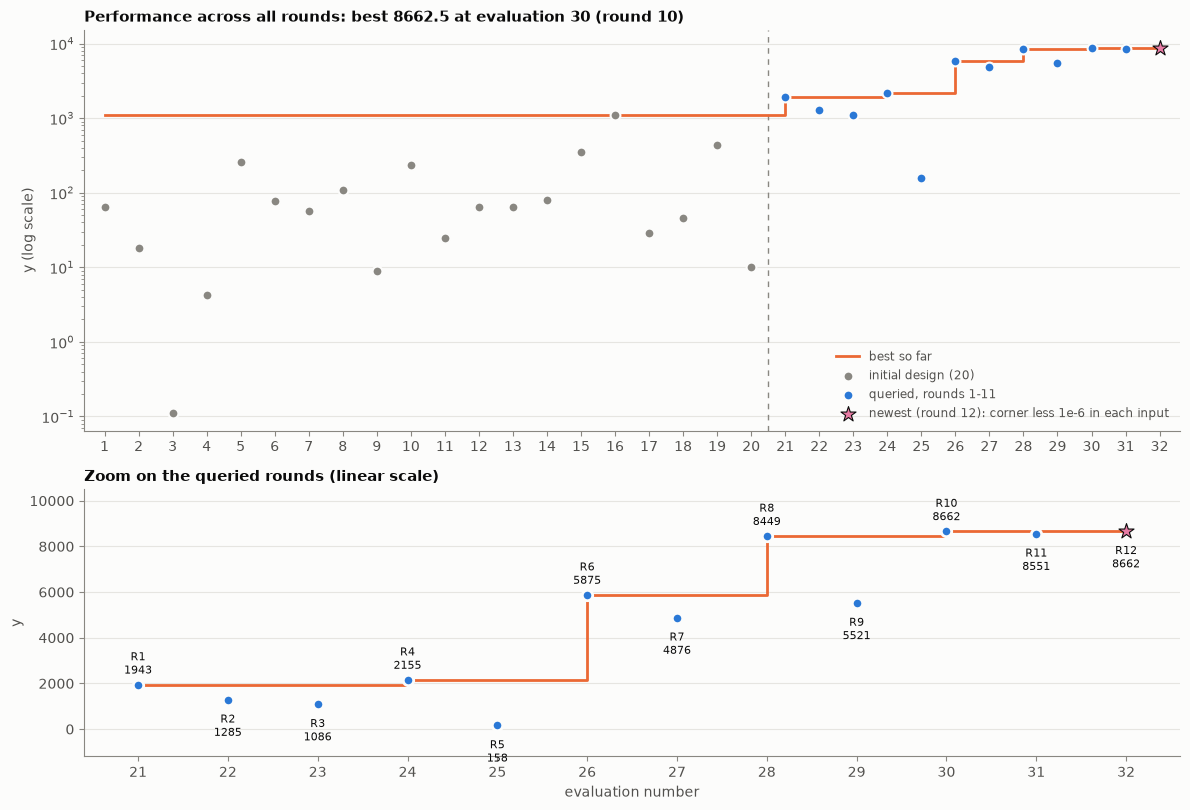

In [10]:
# Fig 5: performance across all rounds (log scale) with a linear zoom on the queried rounds
idx = np.arange(1, n + 1)
bsf = np.maximum.accumulate(np.r_[np.full(N_INITIAL, y[:N_INITIAL].max()), y[N_INITIAL:]])
fig, (ax, az) = plt.subplots(2, 1, figsize=(12, 8.2), height_ratios=[3, 2])
ax.axvline(N_INITIAL + 0.5, color=MUTED, lw=1, ls=(0, (4, 4)))
ax.step(idx, bsf, where="post", color=ORANGE, lw=2, label="best so far", zorder=2)
ax.scatter(idx[:N_INITIAL], y[:N_INITIAL], s=50, color=MUTED, edgecolor=SURFACE, linewidth=1.5,
           label=f"initial design ({N_INITIAL})", zorder=3)
ax.scatter(idx[N_INITIAL:W12], y[N_INITIAL:W12], s=50, color=BLUE, edgecolor=SURFACE, linewidth=1.5,
           label=f"queried, rounds 1-{n - N_INITIAL - 1}", zorder=3)
ax.scatter(idx[W12], y[W12], s=130, marker="*", color=MAGENTA, edgecolor=INK, linewidth=0.8, zorder=4,
           label=f"newest (round {n - N_INITIAL}): corner less 1e-6 in each input")
ax.set_yscale("log"); ax.set_xticks(idx); ax.set_xlim(0.4, n + 0.6)
ax.grid(axis="x", visible=False); ax.set_ylabel("y (log scale)")
ax.set_title(f"Performance across all rounds: best {BEST:.1f} at evaluation {best + 1} (round {best - N_INITIAL + 1})")
ax.legend(frameon=False, loc="lower right", fontsize=8.5, labelcolor=INK2)
q = np.arange(N_INITIAL, n)
az.step(idx[q], bsf[q], where="post", color=ORANGE, lw=2, zorder=2)
for i in q:
    star = i == W12
    az.scatter(idx[i], y[i], s=130 if star else 56, marker="*" if star else "o", color=MAGENTA if star else BLUE,
               edgecolor=INK if star else SURFACE, linewidth=0.8 if star else 2, zorder=3)
    az.annotate(f"R{i - N_INITIAL + 1}\n{y[i]:.0f}", (idx[i], y[i]), xytext=(0, 8 if (y[i] >= bsf[i] - 1e-9 and not star) else -26),
                textcoords="offset points", ha="center", fontsize=8, color=INK)
az.set_xticks(idx[q]); az.set_xlim(N_INITIAL + 0.4, n + 0.6); az.set_ylim(-1200, 10500)
az.grid(axis="x", visible=False); az.set_xlabel("evaluation number"); az.set_ylabel("y")
az.set_title("Zoom on the queried rounds (linear scale)")
fig.tight_layout()